In [4]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
main_pth = '/users/kduecker/hnn-tuning'
import os

pth_mod = os.path.join(main_pth, 'local_hnn/hnn_core/mod')
pth_rslts = os.path.join(main_pth, 'new_cells_dev/optuna/ca_spike')
os.makedirs(pth_rslts, exist_ok=True)

import sys
sys.path.append(os.path.join(main_pth, 'new_cells_dev/utils'))

from cell_builder_utils import l2_params, _get_dends, _get_pyr_soma, Cell
from iascone_mechs_utils import Mechs, get_iascone_params
from plot_utils import fig_conductances, fig_compartments
from functools import partial
from hnn_core.viz import plot_cell_morphology

from matplotlib import colormaps
from scipy import signal
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

cmap = colormaps['viridis']
cols_dist = cmap.colors[0:len(cmap.colors):20]

from iascone_mechs_utils import linear_gbar

In [242]:
model_params = {'soma': {'NaTs2_t_32d': 0, #20_400e-4*2,
                                'SKv3_1': 0,#6_930e-4*1.5,
                                'Nap_Et2': 0,
                                'Ca_HVA': 0,
                                'Ca_LVAst': 0,
                                'pas': 1.0 / 38331,
                                'Ih': 0.001,
                                'SK_E2': 0,
                                'Im': 0},
                        'basal': {'NaTs2_t_32d': 0.008009,
                                  'SKv3_1': 0.000513,
                                  'Ih': 0.001,
                                  'pas':  1.0 / 30000.0},
                        'dend': {'NaTs2_t_32d': 0.0007545577135222227*10,
                                'SKv3_1': 0.008911542253622935,
                                'Ca_HVA': 0.001, #partial(linear_gbar, 0.0001, 0.0005, 300, hotzone=[300,400], hotzone_factor=4),
                                'Ca_LVAst': 0.00001, #partial(linear_gbar, 0.000001, 0.00005, 300, hotzone=[300,400], hotzone_factor=1),
                                'pas': 1.0 /29062,
                                'SK_E2': 0.1,
                                'Ih': 0.0001,
                                'Im': 0.0001,
                                'CaDynamics_E2': {'decay': 60, 'gamma': 0.0025792496905644342/20}},
                        'e_pas': -75,
                        'passive_params': {'cm': 2,
                                           'Ra': 200}}


In [243]:
def flatten_params(nested_params):
    """Flatten nested dictionary into a list of values."""
    flattened = []
    # Flatten compartment conductances
    for comp in ['soma', 'basal', 'dend']:
        for channel, value in nested_params[comp].items():
            if isinstance(value, dict):  # Handle nested CaDynamics_E2
                for param, sub_value in value.items():
                    flattened.append(sub_value)
            else:
                flattened.append(value)
    # Flatten top-level keys
    flattened.append(nested_params['e_pas'])
    # Flatten passive_params
    for param in ['cm', 'Ra']:
        flattened.append(nested_params['passive_params'][param])
    return flattened

In [244]:
flat_list = flatten_params(model_params)
flat_list

[0,
 0,
 0,
 0,
 0,
 2.6088544520101225e-05,
 0.001,
 0,
 0,
 0.008009,
 0.000513,
 0.001,
 3.3333333333333335e-05,
 0.007545577135222227,
 0.008911542253622935,
 0.001,
 1e-05,
 3.440919413667332e-05,
 0.1,
 0.0001,
 0.0001,
 60,
 0.0001289624845282217,
 -75,
 2,
 200]

In [253]:
flat_list = flatten_params(model_params)

reconstructed = {
        'soma': {'NaTs2_t_32d': None, 'SKv3_1': None, 'Nap_Et2': None, 
                 'Ca_HVA': None, 'Ca_LVAst': None, 'pas': None, 'Ih': None, 'SK_E2': None, 'Im': None},
        'basal': {'NaTs2_t_32d': None, 'SKv3_1': None, 'Ih': None, 'pas': None},
        'dend': {'NaTa_t_32d': None, 'SKv3_1': None, 'Ca_HVA': None, 'Ca_LVAst': None,
                 'pas': None, 'SK_E2': None, 'Ih': None, 'Im': None,
                 'CaDynamics_E2': {'decay': None, 'gamma': None}},
        'e_pas': None,
        'passive_params': {'L2Pyr_soma_cm': None, 'L2Pyr_soma_Ra': None,
                           'L2Pyr_dend_cm': None, 'L2Pyr_dend_Ra': None},
    }
    
# Index tracker for flat_list
index = 0

ca_fun_vals = []#np.ones(10,)
ca_index = 0
# Reconstruct compartments
for comp in ['soma', 'basal', 'dend']:
    for channel in reconstructed[comp]:
        if channel == 'CaDynamics_E2':
            print(channel)
            for sub_param in reconstructed[comp][channel]:
                reconstructed[comp][channel][sub_param] = flat_list[index]
                index += 1

        elif (comp == 'dend' and channel == 'Ca_HVA' and len(ca_fun_vals)>0) or (comp == 'dend' and channel == 'Ca_LVAst' and len(ca_fun_vals)>0):
            reconstructed[comp][channel] = partial(linear_gbar,flat_list[index], ca_fun_vals[ca_index], ca_fun_vals[ca_index+1], hotzone=[ca_fun_vals[ca_index+2], ca_fun_vals[ca_index+3]], hotzone_factor=ca_fun_vals[ca_index+4])
            ca_index +=5
            index +=1
        else:
            reconstructed[comp][channel] = flat_list[index]
            index += 1

# Reconstruct e_pas and passive_params
reconstructed['e_pas'] = flat_list[index]
index += 1
for param in reconstructed['passive_params']:
    if 'cm' in param:
        reconstructed['passive_params'][param] = flat_list[-2]
    elif 'Ra' in param:
        reconstructed['passive_params'][param] = flat_list[-1]
    

CaDynamics_E2


In [254]:
reconstructed

{'soma': {'NaTs2_t_32d': 0,
  'SKv3_1': 0,
  'Nap_Et2': 0,
  'Ca_HVA': 0,
  'Ca_LVAst': 0,
  'pas': 2.6088544520101225e-05,
  'Ih': 0.001,
  'SK_E2': 0,
  'Im': 0},
 'basal': {'NaTs2_t_32d': 0.008009,
  'SKv3_1': 0.000513,
  'Ih': 0.001,
  'pas': 3.3333333333333335e-05},
 'dend': {'NaTa_t_32d': 0.007545577135222227,
  'SKv3_1': 0.008911542253622935,
  'Ca_HVA': 0.001,
  'Ca_LVAst': 1e-05,
  'pas': 3.440919413667332e-05,
  'SK_E2': 0.1,
  'Ih': 0.0001,
  'Im': 0.0001,
  'CaDynamics_E2': {'decay': 60, 'gamma': 0.0001289624845282217}},
 'e_pas': -75,
 'passive_params': {'L2Pyr_soma_cm': 2,
  'L2Pyr_soma_Ra': 200,
  'L2Pyr_dend_cm': 2,
  'L2Pyr_dend_Ra': 200}}

In [202]:
# get paramaters
section_params, end_pts, cell_tree = l2_params()

# build sections
section_names = list(end_pts.keys())

v_init = {'all': -65}

sections = _get_dends(section_params, 'L2Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L2Pyr', end_pts['soma'], v_init=v_init['all'])

mech_class = Mechs(pth_mod)

l2pyr= Cell(sections, cell_tree, cell_type = 'L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)


Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


In [203]:
stim_sect = 'apical_1'
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)
h.distance(sec = l2pyr._nrn_sections[stim_sect])


stim = h.IClamp(l2pyr._nrn_sections[stim_sect](0.5))
stim.delay = 20
stim.dur = 1000
stim.amp = 0.25

t = h.Vector().record(h._ref_t)

stim_v = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(1100 * ms)

t_np = t.as_numpy()
v_np = stim_v.as_numpy()

pk = find_peaks(v_np, height=-10, width=0.1, rel_height=0.5)

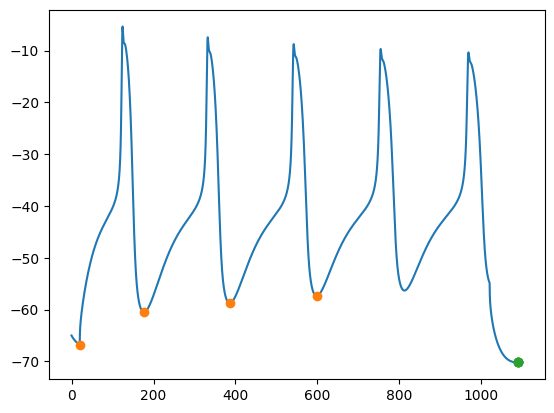

In [204]:
plt.plot(t, stim_v)
plt.plot(t_np[pk[1]['left_bases']], v_np[pk[1]['left_bases']],'o')
plt.plot(t_np[pk[1]['right_bases']], v_np[pk[1]['right_bases']],'o')

#plt.xlim([0, 100])